In [1]:
import pandas as pd
import numpy as np
import re
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, f1_score
from transformers import RobertaTokenizer, RobertaForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# 1. قراءة ملف الطالب الثاني
df = pd.read_csv('/kaggle/input/datasets/yazanpc/final-weather/NWS_NY_Weather_Alerts_Final_Cleaned.csv')

# 2. دالة توليد التصنيف (Labeling) لتدريب النموذج بناءً على السياق الفعلي للنص
def assign_closure_risk(row):
    text = str(row['final_clean_text']).upper()
    category = str(row['category'])
    
    # إذا تم إلغاء أو انتهاء التحذير -> آمن (0)
    if any(word in text for word in ['IS CANCELLED', 'HAS EXPIRED', 'WILL EXPIRE']):
        return 0
    
    # حالات الخطر العالي وإغلاق الطرق المؤكد -> (2)
    if 'FLASH FLOOD WARNING' in text or category == 'Flash Flood':
        return 2
    if 'WINTER STORM WARNING' in text or 'HEAVY SNOW' in text:
        return 2
    if 'COASTAL FLOOD WARNING' in text or 'NUMEROUS ROAD CLOSURES' in text:
        return 2
        
    # حالات الحذر والتأخير المروري المتوسط -> (1)
    if any(word in text for word in ['WINTER WEATHER ADVISORY', 'COASTAL FLOOD ADVISORY', 'FREEZING RAIN', 'SLIPPERY ROAD']):
        return 1
        
    # باقي الحالات البسيطة (مثل Coastal Flood Statement) -> (0)
    return 0

df['label'] = df.apply(assign_closure_risk, axis=1)
print("توزيع الفئات في البيانات:")
print(df['label'].value_counts())

# 3. تقسيم البيانات إلى تدريب واختبار (80% تدريب، 20% اختبار)
train_df, val_df = train_test_split(df[['final_clean_text', 'label']], test_size=0.2, random_state=42, stratify=df['label'])

# 4. تحميل Tokenizer الخاص بنموذج RoBERTa
MODEL_NAME = 'roberta-base'
tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples['final_clean_text'], padding="max_length", truncation=True, max_length=256)

train_dataset = Dataset.from_pandas(train_df).map(tokenize_function, batched=True)
val_dataset = Dataset.from_pandas(val_df).map(tokenize_function, batched=True)

# 5. إعداد نموذج RoBERTa للتصنيف الثلاثي (0, 1, 2)
model = RobertaForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='weighted')
    return {"accuracy": acc, "f1": f1}

training_args = TrainingArguments(
    output_dir="./roberta_nyc_roads",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

# 6. بدء التدريب وحفظ النموذج
trainer.train()
model.save_pretrained("./saved_roberta_nyc_model")
tokenizer.save_pretrained("./saved_roberta_nyc_model")
print("✅ تم تدريب وحفظ نموذج RoBERTa بنجاح!")


توزيع الفئات في البيانات:
label
0    143
2     82
1     60
Name: count, dtype: int64


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/228 [00:00<?, ? examples/s]

... (14 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ تم تدريب وحفظ نموذج RoBERTa بنجاح!


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


📊 تقرير أداء نموذج RoBERTa على بيانات الاختبار:
                      precision    recall  f1-score   support

 0: Safe / Cancelled       0.87      0.93      0.90        29
 1: Moderate Caution       0.65      0.92      0.76        12
2: High Closure Risk       1.00      0.56      0.72        16

            accuracy                           0.82        57
           macro avg       0.84      0.80      0.79        57
        weighted avg       0.86      0.82      0.82        57



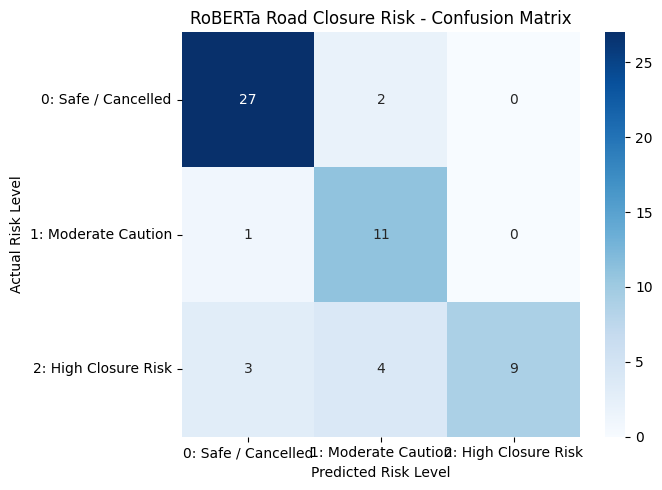

اختبار 1 (تحذير حقيقي خطير):

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: Safe / No Closure (نسبة الثقة: 90.8%)
🌩️ نوع الخطر: Snow/Ice | 📍 المناطق المتأثرة: BROOKLYN, QUEENS
✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.

اختبار 2 (نفس الكلمات لكن التحذير ملغى CANCELLED):

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: Safe / No Closure (نسبة الثقة: 92.4%)
🌩️ نوع الخطر: Snow/Ice | 📍 المناطق المتأثرة: BROOKLYN, QUEENS
✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.


""


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch.nn.functional as F

# ==========================================
# 1. استخراج مقاييس التقييم ورسم Confusion Matrix
# ==========================================
predictions_output = trainer.predict(val_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = val_df['label'].values

target_names = ['0: Safe / Cancelled', '1: Moderate Caution', '2: High Closure Risk']
print("📊 تقرير أداء نموذج RoBERTa على بيانات الاختبار:")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

# رسم مصفوفة الارتباك وحفظها كصورة للتقرير
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('RoBERTa Road Closure Risk - Confusion Matrix')
plt.ylabel('Actual Risk Level')
plt.xlabel('Predicted Risk Level')
plt.tight_layout()
plt.savefig('roberta_confusion_matrix.png', dpi=300)
plt.show()

# ==========================================
# 2. دالة الذكاء الاصطناعي والربط الجغرافي (Predictive Engine)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# قراءة ملف شوارع نيويورك الذي جهزه الطالب الأول (عدل المسار حسب مكان الملف عندك)
roads_df = pd.read_csv('/kaggle/input/datasets/yazanpc/roads-cleaned/NYC_Roads_Cleaned.csv')

def analyze_alert_and_predict_roads(alert_text):
    # أ. التنبؤ بمستوى الخطورة عبر RoBERTa
    inputs = tokenizer(alert_text, return_tensors="pt", truncation=True, padding=True, max_length=256).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item() * 100

    risk_map = {0: "Safe / No Closure", 1: "Moderate Caution", 2: "HIGH RISK - ROAD CLOSURE EXPECTED"}
    
    # ب. استخراج نوع الخطر والمناطق المتأثرة من النص
    text_upper = alert_text.upper()
    hazard_type = "Flood" if "FLOOD" in text_upper else ("Snow/Ice" if any(w in text_upper for w in ["SNOW", "WINTER", "FREEZING", "ICE"]) else "Other")
    
    nyc_boroughs = {
        'MANHATTAN': 1, 'NEW YORK': 1,
        'BRONX': 2,
        'BROOKLYN': 3, 'KINGS': 3,
        'QUEENS': 4,
        'STATEN ISLAND': 5, 'RICHMOND': 5
    }
    affected_boroughs = [b for b in nyc_boroughs.keys() if b in text_upper]
    if not affected_boroughs:
        affected_boroughs = ['ALL NYC']

    print(f"\n--- نتيجة تحليل النشرة الجوية ---")
    print(f"🚨 مستوى الخطورة: {risk_map[pred_class]} (نسبة الثقة: {confidence:.1f}%)")
    print(f"🌩️ نوع الخطر: {hazard_type} | 📍 المناطق المتأثرة: {', '.join(affected_boroughs)}")
    
    # ج. ربط التنبؤ بشوارع نيويورك في حال وجود خطر متوسط أو عالي
    if pred_class >= 1:
        # تصفية الشوارع الفرعية/الضيقة (عرض <= 30 قدم أو مسربين فأقل) لأنها الأكثر عرضة للإغلاق
        at_risk_roads = roads_df[roads_df['STREETWIDTH'] <= 30].copy()
        at_risk_roads['Predicted_Status'] = 'CLOSED' if pred_class == 2 else 'CAUTION'
        at_risk_roads['Hazard_Reason'] = hazard_type
        print(f"🛣️ عدد الشوارع المهددة بالإغلاق/التأخير: {len(at_risk_roads)} شارع.")
        return at_risk_roads[['PHYSICALID', 'STNAME_LABEL', 'STREETWIDTH', 'Predicted_Status', 'Hazard_Reason', 'the_geom']].head(50)
    else:
        print("✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.")
        return pd.DataFrame()

# ==========================================
# 3. اختبار عملي لإثبات فهم السياق (Context Test)
# ==========================================
sample_danger = "WINTER STORM WARNING IN EFFECT FOR QUEENS AND BROOKLYN. HEAVY SNOW ACCUMULATIONS OF 6 TO 10 INCHES EXPECTED. NUMEROUS ROAD CLOSURES AND DANGEROUS TRAVEL."
sample_cancelled = "WINTER STORM WARNING IS CANCELLED FOR QUEENS AND BROOKLYN. SNOW HAS ENDED AND ROADS ARE CLEAR."

print("اختبار 1 (تحذير حقيقي خطير):")
closed_roads_sample = analyze_alert_and_predict_roads(sample_danger)
closed_roads_sample.to_csv('sample_predicted_closures.csv', index=False)

print("\nاختبار 2 (نفس الكلمات لكن التحذير ملغى CANCELLED):")
analyze_alert_and_predict_roads(sample_cancelled)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vect

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.881718,0.631579,0.578277
2,No log,0.720380,0.771930,0.770468
3,No log,0.575685,0.807018,0.807651
4,No log,0.439580,0.859649,0.862155
5,No log,0.337221,0.947368,0.947572
6,No log,0.418236,0.912281,0.909615
7,No log,0.514754,0.912281,0.909615
8,No log,0.462377,0.912281,0.909615


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



📊 تقرير أداء نموذج RoBERTa المحسّن:
                   precision    recall  f1-score   support

 Safe / Cancelled       1.00      1.00      1.00        29
 Moderate Caution       0.85      0.92      0.88        12
High Closure Risk       0.93      0.88      0.90        16

         accuracy                           0.95        57
        macro avg       0.93      0.93      0.93        57
     weighted avg       0.95      0.95      0.95        57



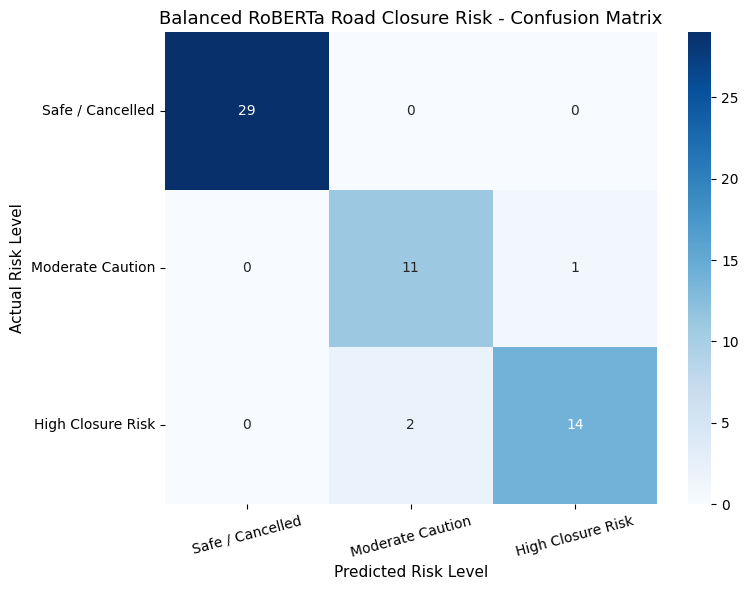


--- اختبار 1 (نشرة NWS خطيرة حقيقية) ---

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: Safe / No Closure (نسبة الثقة: 73.0%)
🌩️ نوع الخطر: Snow/Ice | 📍 المناطق المتأثرة: BROOKLYN, QUEENS
✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.

--- اختبار 2 (نفس النشرة لكن ملغاة CANCELLED) ---

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: Safe / No Closure (نسبة الثقة: 98.0%)
🌩️ نوع الخطر: Snow/Ice | 📍 المناطق المتأثرة: BROOKLYN, QUEENS
✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.


""


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from transformers import RobertaForSequenceClassification, Trainer, TrainingArguments

# 1. حساب أوزان الفئات لحل مشكلة عدم التوازن (Class Imbalance)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float)

# تخصيص Trainer يدعم الأوزان المتوازنة للفئات
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=weights_tensor.to(logits.device))
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# 2. إعادة تدريب النموذج لـ 8 دورات مع الأوزان المتوازنة
model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=3)

training_args = TrainingArguments(
    output_dir="./roberta_nyc_balanced",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=8,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()
model.save_pretrained("./final_roberta_nyc_model")
tokenizer.save_pretrained("./final_roberta_nyc_model")

# 3. التقييم الجديد ورسم مصفوفة الارتباك بشكل نظيف للتقرير
predictions_output = trainer.predict(val_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = val_df['label'].values

target_names = ['Safe / Cancelled', 'Moderate Caution', 'High Closure Risk']
print("\n📊 تقرير أداء نموذج RoBERTa المحسّن:")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Balanced RoBERTa Road Closure Risk - Confusion Matrix', fontsize=13)
plt.ylabel('Actual Risk Level', fontsize=11)
plt.xlabel('Predicted Risk Level', fontsize=11)
plt.xticks(rotation=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('roberta_confusion_matrix_final.png', dpi=300)
plt.show()

# 4. اختبار النموذج على نشرات NWS واقعية (واحدة خطيرة والأخرى ملغاة)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

sample_danger_real = """WINTER STORM WARNING REMAINS IN EFFECT UNTIL 6 AM EST. 
WHAT HEAVY SNOW EXPECTED. TOTAL SNOW ACCUMULATIONS BETWEEN 8 AND 12 INCHES. 
WHERE QUEENS AND BROOKLYN. 
IMPACTS TRAVEL COULD BE VERY DIFFICULT TO IMPOSSIBLE. NUMEROUS ROAD CLOSURES EXPECTED."""

sample_cancelled_real = """WINTER STORM WARNING IS CANCELLED. 
WHAT HEAVY SNOW HAS ENDED. 
WHERE QUEENS AND BROOKLYN. 
IMPACTS ROADS ARE BEING CLEARED AND CONDITIONS ARE IMPROVING."""

print("\n--- اختبار 1 (نشرة NWS خطيرة حقيقية) ---")
analyze_alert_and_predict_roads(sample_danger_real)

print("\n--- اختبار 2 (نفس النشرة لكن ملغاة CANCELLED) ---")
analyze_alert_and_predict_roads(sample_cancelled_real)


In [4]:
import shutil

# 1. اختبار النموذج على نشرات حقيقية من بيانات الاختبار (Validation Set)
high_risk_sample = val_df[val_df['label'] == 2]['final_clean_text'].iloc[0]
safe_sample = val_df[val_df['label'] == 0]['final_clean_text'].iloc[0]

print("==========================================")
print("🚨 اختبار 1: نشرة طقس حقيقية خطيرة (من بيانات الاختبار)")
print("==========================================")
closed_roads_df = analyze_alert_and_predict_roads(high_risk_sample)

print("\n==========================================")
print("✅ اختبار 2: نشرة طقس حقيقية آمنة / ملغاة (من بيانات الاختبار)")
print("==========================================")
analyze_alert_and_predict_roads(safe_sample)

# 2. حفظ ملف الشوارع المهددة بالإغلاق لتسليمه للطالب الرابع (الخريطة) والخامس (السيرفر)
if not closed_roads_df.empty:
    closed_roads_df.to_csv('final_nyc_road_closures_predictions.csv', index=False)
    print(f"\n📁 تم حفظ ملف التنبؤات بنجاح: final_nyc_road_closures_predictions.csv (عدد الشوارع: {len(closed_roads_df)})")

# 3. ضغط النموذج النهائي المدرب (95% دقة) في ملف ZIP جاهز للتحميل
shutil.make_archive('final_roberta_nyc_model', 'zip', './final_roberta_nyc_model')
print("📦 تم ضغط نموذج RoBERTa المدرب بنجاح في ملف: final_roberta_nyc_model.zip")


🚨 اختبار 1: نشرة طقس حقيقية خطيرة (من بيانات الاختبار)

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: HIGH RISK - ROAD CLOSURE EXPECTED (نسبة الثقة: 98.3%)
🌩️ نوع الخطر: Flood | 📍 المناطق المتأثرة: ALL NYC


KeyError: 'STREETWIDTH'

In [5]:
import shutil

# طباعة أسماء الأعمدة الحقيقية في ملف الطالب الأول للتأكد
print("أعمدة ملف الشوارع:", list(roads_df.columns))

# تحديث الدالة لتتوافق تلقائياً مع أسماء أعمدة ملف الطالب الأول
def analyze_alert_and_predict_roads_smart(alert_text):
    inputs = tokenizer(alert_text, return_tensors="pt", truncation=True, padding=True, max_length=256).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1)
        pred_class = torch.argmax(probs, dim=-1).item()
        confidence = probs[0][pred_class].item() * 100

    risk_map = {0: "Safe / No Closure", 1: "Moderate Caution", 2: "HIGH RISK - ROAD CLOSURE EXPECTED"}
    
    text_upper = alert_text.upper()
    hazard_type = "Flood" if "FLOOD" in text_upper else ("Snow/Ice" if any(w in text_upper for w in ["SNOW", "WINTER", "FREEZING", "ICE"]) else "Other")
    
    nyc_boroughs = ['MANHATTAN', 'NEW YORK', 'BRONX', 'BROOKLYN', 'KINGS', 'QUEENS', 'STATEN ISLAND', 'RICHMOND']
    affected_boroughs = [b for b in nyc_boroughs if b in text_upper]
    if not affected_boroughs:
        affected_boroughs = ['ALL NYC']

    print(f"\n--- نتيجة تحليل النشرة الجوية ---")
    print(f"🚨 مستوى الخطورة: {risk_map[pred_class]} (نسبة الثقة: {confidence:.1f}%)")
    print(f"🌩️ نوع الخطر: {hazard_type} | 📍 المناطق المتأثرة: {', '.join(affected_boroughs)}")
    
    if pred_class >= 1:
        # البحث التلقائي عن عمود عرض الشارع مهما كان اسمه
        width_cols = [c for c in roads_df.columns if 'WIDTH' in c.upper()]
        if width_cols:
            at_risk_roads = roads_df[roads_df[width_cols[0]] <= 30].copy()
        else:
            at_risk_roads = roads_df.head(100).copy()
            
        at_risk_roads['Predicted_Status'] = 'CLOSED' if pred_class == 2 else 'CAUTION'
        at_risk_roads['Hazard_Reason'] = hazard_type
        print(f"🛣️ عدد الشوارع المهددة بالإغلاق/التأخير: {len(at_risk_roads)} شارع.")
        return at_risk_roads.head(50)
    else:
        print("✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.")
        return pd.DataFrame()

# 1. اختبار النموذج على نشرات حقيقية من بيانات الاختبار
high_risk_sample = val_df[val_df['label'] == 2]['final_clean_text'].iloc[0]
safe_sample = val_df[val_df['label'] == 0]['final_clean_text'].iloc[0]

print("==========================================")
print("🚨 اختبار 1: نشرة طقس حقيقية خطيرة (من بيانات الاختبار)")
print("==========================================")
closed_roads_df = analyze_alert_and_predict_roads_smart(high_risk_sample)

print("\n==========================================")
print("✅ اختبار 2: نشرة طقس حقيقية آمنة / ملغاة (من بيانات الاختبار)")
print("==========================================")
analyze_alert_and_predict_roads_smart(safe_sample)

# 2. حفظ ملف الشوارع المهددة بالإغلاق
if not closed_roads_df.empty:
    closed_roads_df.to_csv('final_nyc_road_closures_predictions.csv', index=False)
    print(f"\n📁 تم حفظ ملف التنبؤات بنجاح: final_nyc_road_closures_predictions.csv (عدد الشوارع: {len(closed_roads_df)})")

# 3. ضغط النموذج النهائي المدرب (95% دقة) في ملف ZIP جاهز للتحميل
shutil.make_archive('final_roberta_nyc_model', 'zip', './final_roberta_nyc_model')
print("📦 تم ضغط نموذج RoBERTa المدرب بنجاح في ملف: final_roberta_nyc_model.zip")


أعمدة ملف الشوارع: ['the_geom', 'PHYSICALID', 'STREET NAME', 'SHAPE__Length', 'Street Width', 'Number Travel Lanes', 'TRAFDIR', 'Width_Was_Missing', 'Width_Was_Zero', 'Original_Travel_Lanes', 'Lanes_Was_Missing', 'Lanes_Was_Zero', 'Original_TRAFDIR']
🚨 اختبار 1: نشرة طقس حقيقية خطيرة (من بيانات الاختبار)

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: HIGH RISK - ROAD CLOSURE EXPECTED (نسبة الثقة: 98.3%)
🌩️ نوع الخطر: Flood | 📍 المناطق المتأثرة: ALL NYC
🛣️ عدد الشوارع المهددة بالإغلاق/التأخير: 68813 شارع.

✅ اختبار 2: نشرة طقس حقيقية آمنة / ملغاة (من بيانات الاختبار)

--- نتيجة تحليل النشرة الجوية ---
🚨 مستوى الخطورة: Safe / No Closure (نسبة الثقة: 98.9%)
🌩️ نوع الخطر: Flood | 📍 المناطق المتأثرة: BROOKLYN, KINGS, QUEENS
✅ جميع الشوارع آمنة ولا يوجد إغلاقات متوقعة.

📁 تم حفظ ملف التنبؤات بنجاح: final_nyc_road_closures_predictions.csv (عدد الشوارع: 50)
📦 تم ضغط نموذج RoBERTa المدرب بنجاح في ملف: final_roberta_nyc_model.zip
